# 01 Data: where the data comes from, and is it right?

| | |
|---|---|
| **Question** | Where does the data come from, how many revisions are in each cohort, and do the counts make sense? |
| **Answer** | history cohort: **<!--fact:history_revisions-->295,016<!--/fact--> revisions** (FINAL); live cohort: **<!--fact:live_revisions-->279,466<!--/fact--> revisions** (PROVISIONAL). History cohort (reverts within 20 days): non-bot revert rate <!--fact:history_revert_rate_non_bot_pct-->7.43<!--/fact-->%, median time to revert <!--fact:history_median_T_h-->1.02<!--/fact--> h. |
| **Time to run** | about 10 seconds |
| **Needs** | `data/tables/` and `data/parsed/` (from the data release or the pipeline). Optional: the local MongoDB (one cell) and `data/history/` (one cross-check); those cells say SKIPPED if missing. |

Human editors appear only as pseudonyms (`editor_` + 10 hex digits). Bots keep their names. All data times are UTC. Words: see `GLOSSARY.md`. Numbers: see `report/FACTS.md`. Every number in the text comes from there (`report/sync_notebook_text.py` copies it).

## Setup

**What:** Finds the project folder, imports `config.py` and the report helpers, and prints the data version.

**Why:** Every rule and path comes from `config.py`. The data version tells you which data release you have.

**You should see:** `DATA_VERSION: data-v1` (or a later version) and the path of the Python program.

In [1]:
# Set up the paths: this notebook is in ec-hw2/notebooks/, the project code is in ec-hw2/.
import sys, time, json
from pathlib import Path
HW2 = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd() / "ec-hw2"
sys.path.insert(0, str(HW2))
import config
import pandas as pd
from tabulate import tabulate
from IPython.display import Image, Markdown, display
from report import build_facts as facts      # FACTS.md helpers (check, tables with pseudonyms)
from report import make_figures as figs      # the report charts
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)
T0 = time.time()

def _cell(v):
    if v is None or v is pd.NA or (isinstance(v, float) and v != v):
        return ""
    if isinstance(v, float):
        return f"{v:,.1f}" if abs(v) >= 1000 else f"{v:.4g}"
    return v

def show(df, n=None):
    """Print a table as text (it reads well on GitHub). Each cell keeps its own type."""
    d = df if n is None else df.head(n)
    rows = [[_cell(v) for v in r] for r in d.astype(object).itertuples(index=False)]
    print(tabulate(rows, headers=list(d.columns), tablefmt="github"))

print("DATA_VERSION:", config.DATA_VERSION)
print("Python:", sys.executable)

DATA_VERSION: data-v1
Python: /Users/scottnelson/Desktop/226/truth-lag/.venv/bin/python3


## 1. Where the data comes from

- **Live stream.** On the VPS (`vps-coin`), 2 systemd units (`truthlag-capture-a` and `-b`) read 3 Wikimedia EventStreams all the time and save every English Wikipedia event as `.ndjson.gz` files, one folder per hour of `meta.dt`. The script is `ingest/vps/capture.py` (repo root).
- **History dump.** On the VPS, `ingest/vps/filter_history.py` read the 2026-09 MediaWiki History dump once and wrote 2 Parquet files: the 2026-09-08 to 2026-09-10 namespace-0 cohort and a slim file with every September revision.
- **rsync.** Both are copied to Scott's Mac with `rsync -az --partial` (never `--delete`).
- **No live connections from laptops.** Nobody opens EventStreams from a laptop: the VPS needs both connection slots. This notebook only reads files that are already on disk.

**What:** Shows the architecture picture and the sources from `config.py`, and counts the raw files in the Mac copy.

**Why:** So you can see where every number in this notebook comes from.

**You should see:** The data-flow picture, the 3 stream names, the times that the 2 capture units replay from (`config.py`: 2026-10-19 23:00 UTC and 2026-10-17 00:00 UTC), the dump URL and size (557,344,652 bytes), and the raw file count per stream.

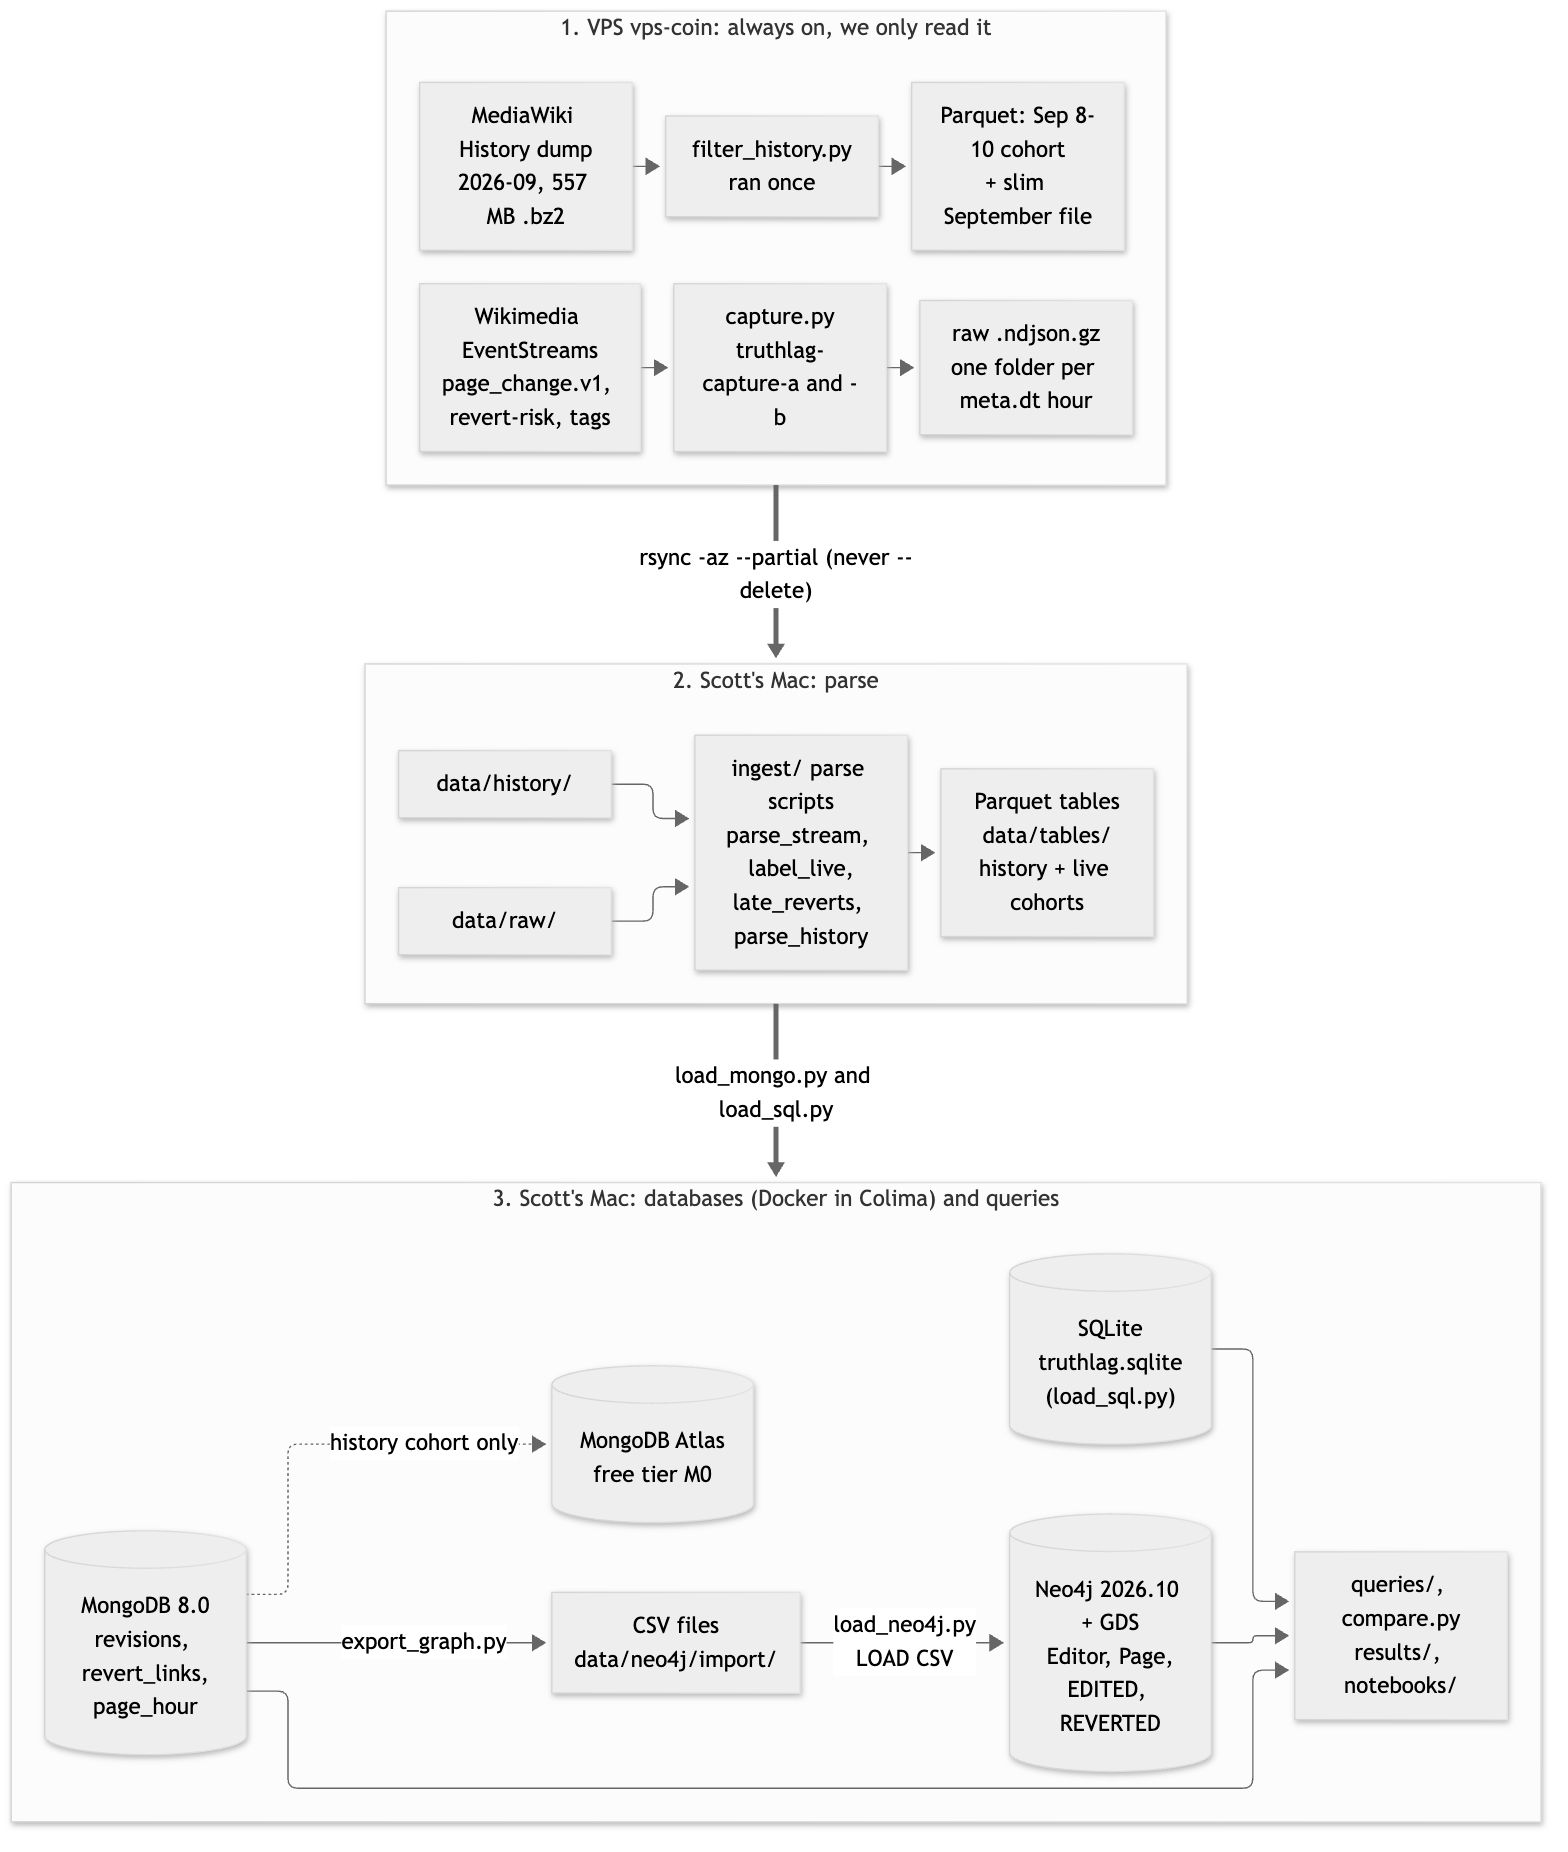

Streams: mediawiki.page_change.v1, mediawiki.page_revert_risk_prediction_change.v1, mediawiki.revision-tags-change
Capture a (page_change + revert risk) since: 2026-10-19T23:00:00+00:00
Capture b (tags) since: 2026-10-17T00:00:00+00:00
History dump: https://dumps.wikimedia.org/other/mediawiki_history/2026-09/enwiki/2026-09.enwiki.2026-09.tsv.bz2
Dump size: 557,344,652 bytes; snapshot 2026-09
| stream                                          |   part files |    MB |
|-------------------------------------------------|--------------|-------|
| mediawiki.page_change.v1                        |          145 | 235.5 |
| mediawiki.page_revert_risk_prediction_change.v1 |          143 | 134.5 |
| mediawiki.revision-tags-change                  |          202 | 193.6 |


In [2]:
display(Image(filename=str(HW2 / "report" / "figures" / "architecture.png"), width=700))
print("Streams:", ", ".join(config.STREAM_DIRS))
print("Capture a (page_change + revert risk) since:", config.CAPTURE_A_SINCE.isoformat())
print("Capture b (tags) since:", config.CAPTURE_B_SINCE.isoformat())
print("History dump:", config.HISTORY_SOURCE_URL)
print(f"Dump size: {config.HISTORY_SOURCE_BYTES:,} bytes; snapshot {config.HISTORY_SNAPSHOT}")
rows = []
for s in config.STREAM_DIRS:
    files = list((config.RAW_DIR / s).glob(config.RAW_GLOB))
    rows.append({"stream": s, "part files": len(files),
                 "MB": round(sum(f.stat().st_size for f in files) / 1e6, 1)})
show(pd.DataFrame(rows))

## 2. Counts per cohort and the filters

**What:** Shows how many rows each filter dropped, for both cohorts, from the summaries that `ingest/parse_history.py` and `ingest/label_live.py` wrote. Then it counts the rows of the final Parquet tables again.

**Why:** The report must say which rows we dropped and why (DATA_MODEL.md, section 3).

**You should see:** History: <!--fact:history_file_rows-->300,564<!--/fact--> rows in the filtered file, <!--fact:history_revisions-->295,016<!--/fact--> after the filters. Live: <!--fact:live_page_change_events-->639,330<!--/fact--> page_change events, <!--fact:live_revisions-->279,466<!--/fact--> revisions after the filters. The last column says OK when the steps add up.

In [3]:
import pyarrow.parquet as pq
hs = json.loads((config.TABLES_DIR / "history_summary.json").read_text())
ls = json.loads((config.TABLES_DIR / "live_summary.json").read_text())
d = hs["rows"]["dropped"]
hist = [("rows in the filtered dump file (current namespace 0)", hs["rows"]["cohort_file_rows"]),
        ("dropped: namespace at edit time is not 0 (page moved later)", -d["namespace_historical_not_0"]),
        ("dropped: null revision, same sha1 as the parent", -d["null_revision_same_sha1"]),
        ("dropped: null revision by its comment (page moves, protection)", -d["null_revision_comment"]),
        ("dropped: outside the window / not a revision", -(d["outside_window"] + d["not_revision_create"]))]
c = ls["cohort"]
live = [("page_change events (all namespaces, all kinds)", c["page_change_events"])]
live += [(f"dropped: kind = {k}", -v) for k, v in c["drops"]["kind_not_create_or_edit"].items()]
live += [("dropped: namespace not 0", -c["drops"]["namespace_not_0"]),
         ("dropped: edit time outside 2026-10-20 to 2026-10-22", -c["drops"]["outside_window"]),
         ("dropped: duplicate rev_id", -c["drops"]["duplicate_rev_id"]),
         ("dropped: null revision", -c["drops"]["null_revision"])]
n_hist = pq.ParquetFile(config.TABLES_DIR / "history_revisions.parquet").metadata.num_rows
n_live = pq.ParquetFile(config.TABLES_DIR / "live_revisions.parquet").metadata.num_rows
for name, steps, final in (("history cohort", hist, n_hist), ("live cohort", live, n_live)):
    df = pd.DataFrame(steps, columns=["step", "rows"])
    print(f"=== {name}")
    show(df)
    total = int(df["rows"].sum())
    print(f"sum of the steps = {total:,}; rows in the final Parquet table = {final:,} -> "
          f"{'OK' if total == final else 'DIFFERENT'}\n")

=== history cohort
| step                                                           |   rows |
|----------------------------------------------------------------|--------|
| rows in the filtered dump file (current namespace 0)           | 300564 |
| dropped: namespace at edit time is not 0 (page moved later)    |  -4265 |
| dropped: null revision, same sha1 as the parent                |   -568 |
| dropped: null revision by its comment (page moves, protection) |   -715 |
| dropped: outside the window / not a revision                   |      0 |
sum of the steps = 295,016; rows in the final Parquet table = 295,016 -> OK

=== live cohort
| step                                                |    rows |
|-----------------------------------------------------|---------|
| page_change events (all namespaces, all kinds)      |  639330 |
| dropped: kind = delete                              |  -16141 |
| dropped: kind = move                                |   -4088 |
| dropped: kind = undelete

**What:** Counts the revisions per user kind in each cohort (from the Parquet tables).

**Why:** The user kind (bot, temporary, registered, unknown) drives most results. `config.user_kind()` sets it the same way in both cohorts.

**You should see:** Registered users make most edits; temporary accounts about 13% and bots about 11%; the live cohort has no `unknown` editors.

In [4]:
hist_rev = pd.read_parquet(config.TABLES_DIR / "history_revisions.parquet",
                           columns=["user_kind", "is_bot", "reverted", "reverted_any", "secs_to_revert",
                                    "mw_reverted_tag", "rev_id"])
live_rev = pd.read_parquet(config.TABLES_DIR / "live_revisions.parquet", columns=["user_kind", "rev_id", "followup_s"])
kinds = pd.DataFrame({"history": hist_rev["user_kind"].value_counts(),
                      "live": live_rev["user_kind"].value_counts()}).fillna(0).astype(int)
kinds["history %"] = (100 * kinds["history"] / kinds["history"].sum()).round(2)
kinds["live %"] = (100 * kinds["live"] / kinds["live"].sum()).round(2)
show(kinds.reset_index(names="user_kind"))
print("duplicate rev_id: history", hist_rev["rev_id"].duplicated().sum(), "| live", live_rev["rev_id"].duplicated().sum())

| user_kind   |   history |   live |   history % |   live % |
|-------------|-----------|--------|-------------|----------|
| bot         |     33483 |  31973 |       11.35 |    11.44 |
| registered  |    223366 | 211179 |       75.71 |    75.57 |
| temporary   |     38164 |  36314 |       12.94 |    12.99 |
| unknown     |         3 |      0 |        0    |     0    |
duplicate rev_id: history 0 | live 0


## 3. Capture coverage and gaps

**What:** Shows the capture coverage: the first and the newest parsed event of each stream, the gaps (two events more than 120 s apart), and the files that were cut short. Then it draws events per hour.

**Why:** A hole in the capture would hide reverts. A file that was still open when rsync copied it has no gzip end yet; `parse_stream.py` keeps all its complete lines.

**You should see:** page_change from <!--fact:capture_page_change_first_utc-->2026-10-19T23:00:00Z<!--/fact--> to <!--fact:capture_page_change_last_utc-->2026-10-24T07:59:59Z<!--/fact--> (the newest parsed event) with <!--fact:capture_page_change_gaps-->0<!--/fact--> gaps; revert-risk with <!--fact:capture_revert_risk_gaps-->2<!--/fact--> short gaps (<!--fact:capture_revert_risk_gap_s_total-->546<!--/fact--> s in all); tags from <!--fact:capture_tags_first_utc-->2026-10-17T01:30:18Z<!--/fact-->. 0 duplicate `meta.id` after the dedupe. Then the chart.

| stream                                          | first meta.dt               | newest parsed meta.dt       |   events |   duplicate meta.id |   gaps > 120 s | files cut short   |
|-------------------------------------------------|-----------------------------|-----------------------------|----------|---------------------|----------------|-------------------|
| mediawiki.page_change.v1                        | 2026-10-19T23:00:00.504000Z | 2026-10-24T07:59:59.973000Z |   639330 |                   0 |              0 | 11 of 144         |
| mediawiki.page_revert_risk_prediction_change.v1 | 2026-10-19T23:00:00.684000Z | 2026-10-24T07:59:59.951000Z |   399115 |                   0 |              2 | 10 of 142         |
| mediawiki.revision-tags-change                  | 2026-10-17T01:30:18.742000Z | 2026-10-24T07:59:59.879000Z |  1059190 |                   0 |              0 | 27 of 201         |

Gaps (capture_gaps.csv):
| stream                                          | gap_start   

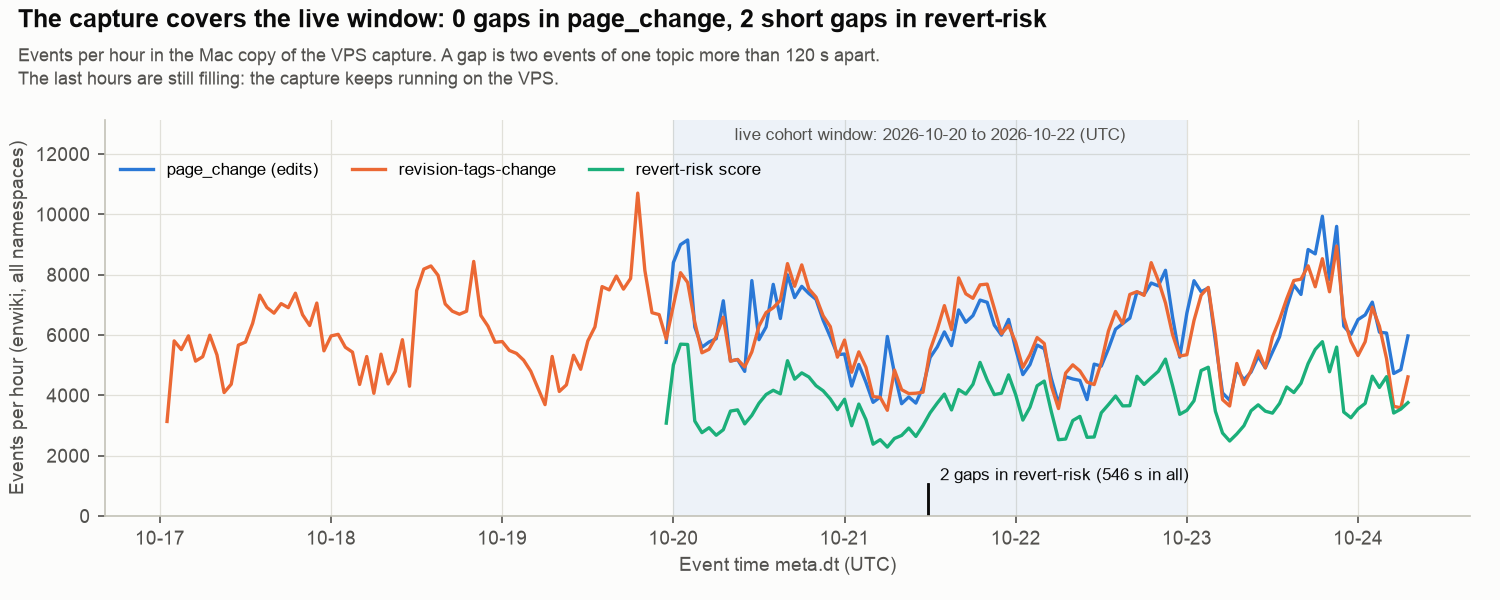

In [5]:
sp = json.loads((config.PARSED_DIR / "_SUCCESS_parsed.json").read_text())
rows = []
for name, s in sp["streams"].items():
    rows.append({"stream": name, "first meta.dt": s["first_meta_dt"], "newest parsed meta.dt": s["last_meta_dt"],
                 "events": s["rows"], "duplicate meta.id": s["duplicate_meta_id"], "gaps > 120 s": s["gaps"],
                 "files cut short": f'{s["cut_short_file_count"]} of {s["files_read"]}'})
show(pd.DataFrame(rows))
gaps = pd.read_csv(config.PARSED_DIR / "capture_gaps.csv")
print("\nGaps (capture_gaps.csv):")
show(gaps[["stream", "gap_start", "gap_end", "gap_s"]])
display(Image(filename=str(figs.capture_coverage_figure())))

## 4. Basic checks

**What:** Runs 4 basic checks: (a) the history count against Wikistats, (b) the non-bot revert rate, (c) the median time to revert, also on the 4-day horizon of the live cohort, (d) the 4-day revert rate of both cohorts.

**Why:** If the counts are far from an outside source, or the rates are far from what earlier work found, something in the pipeline is wrong.

**You should see:**
- (a) Within 2% of Wikistats.
- (b) <!--fact:history_revert_rate_non_bot_pct-->7.43<!--/fact-->% (expected 5-8%).
- (c) <!--fact:history_median_T_non_bot_h-->0.96<!--/fact--> h for non-bot edits and <!--fact:history_median_T_h-->1.02<!--/fact--> h for all edits (reverts within 20 days). On the 4-day horizon of the live cohort: history <!--fact:history_median_T_4d_s-->1,942<!--/fact--> s, live <!--fact:live_median_T_s-->1,088<!--/fact--> s (PROVISIONAL). The plan's first probe said 3.8 h. The cross-check on 2026-09-01 in the slim file gives about 0.7 h, so the probe number was wrong, not the cohort.
- (d) <!--fact:mongo_q5_history_revert_rate_4d_pct-->5.98<!--/fact-->% (history) and <!--fact:mongo_q5_live_revert_rate_4d_pct-->6.18<!--/fact-->% (live, PROVISIONAL).

In [6]:
W = facts.WIKISTATS_CONTENT_EDITS
file_rows = hs["rows"]["cohort_file_rows"]
a_file = 100 * (file_rows - W) / W
a_clean = 100 * (len(hist_rev) - W) / W
print(f"(a) Wikistats content edits 2026-09-08..10: {W:,}. Filtered file: {file_rows:,} ({a_file:+.2f}%). "
      f"After our filters: {len(hist_rev):,} ({a_clean:+.2f}%) -> {'OK' if abs(a_file) < 2 and abs(a_clean) < 2 else 'CHECK'}")

non_bot = hist_rev[~hist_rev["is_bot"]]
rate_nb = non_bot["reverted"].mean()
print(f"(b) non-bot revert rate (reverted within 20 days): {100 * rate_nb:.2f}% "
      f"-> {'OK' if 0.05 <= rate_nb <= 0.08 else 'CHECK'} (expected 5-8%)")

t_nb = non_bot.loc[non_bot["reverted"], "secs_to_revert"].astype(float)
t_all = hist_rev.loc[hist_rev["reverted"], "secs_to_revert"].astype(float)
print(f"(c) median time to revert: non-bot {t_nb.median():,.0f} s = {t_nb.median() / 3600:.2f} h; "
      f"all {t_all.median():,.0f} s = {t_all.median() / 3600:.2f} h (reverts within 20 days)")
# The live cohort is followed for 4 days only, so compare it with the history reverts within 4 days.
t_4d = t_all[t_all <= config.LIVE_FOLLOWUP_S]
live_links = pd.read_parquet(config.TABLES_DIR / "live_revert_links.parquet", columns=["T_s", "within_followup"])
t_live = live_links.loc[live_links["within_followup"], "T_s"].astype(float)
print(f"    on the 4-day horizon: history median {t_4d.median():,.0f} s = {t_4d.median() / 3600:.2f} h "
      f"({len(t_4d):,} reverts); live median {t_live.median():,.0f} s = {t_live.median() / 3600:.2f} h "
      f"({len(t_live):,} reverts, PROVISIONAL)")
slim = config.HISTORY_DIR / config.HISTORY_SLIM_FILE
if slim.exists():
    # Independent cross-check on the raw slim file (strings): human edits of 2026-09-01, namespace 0.
    s = pd.read_parquet(slim, columns=["event_timestamp", "page_namespace", "event_user_is_bot_by",
                                       "revision_is_identity_reverted", "revision_seconds_to_identity_revert"])
    s = s[(s["page_namespace"] == "0") & s["event_timestamp"].str.startswith("2026-09-01")]
    s = s[~s["event_user_is_bot_by"].fillna("").str.contains("group")]
    rv = s["revision_is_identity_reverted"] == "true"
    t1 = pd.to_numeric(s.loc[rv, "revision_seconds_to_identity_revert"])
    print(f"    cross-check, 2026-09-01 human namespace-0 edits in the slim file: {len(s):,} edits, "
          f"{100 * rv.mean():.2f}% reverted (any time), median T {t1.median() / 3600:.2f} h, "
          f"{100 * (t1 > 86400).mean():.0f}% over 1 day")
else:
    print("    cross-check SKIPPED: data/history/ is not on this computer")

q5 = pd.read_csv(config.RESULTS_DIR / "mongo_q5_truth_lag_preview.csv")
r4 = q5[(q5["user_kind"] == "all") & (q5["wait"] == "4 d")].set_index("cohort")["revert_rate_4d"]
print(f"(d) revert rate within 4 days: history {100 * r4['history']:.2f}%, live {100 * r4['live']:.2f}% (live is PROVISIONAL)")

(a) Wikistats content edits 2026-09-08..10: 298,802. Filtered file: 300,564 (+0.59%). After our filters: 295,016 (-1.27%) -> OK
(b) non-bot revert rate (reverted within 20 days): 7.43% -> OK (expected 5-8%)
(c) median time to revert: non-bot 3,440 s = 0.96 h; all 3,660 s = 1.02 h (reverts within 20 days)
    on the 4-day horizon: history median 1,942 s = 0.54 h (17,646 reverts); live median 1,088 s = 0.30 h (17,259 reverts, PROVISIONAL)


    cross-check, 2026-09-01 human namespace-0 edits in the slim file: 106,471 edits, 7.25% reverted (any time), median T 0.67 h, 22% over 1 day
(d) revert rate within 4 days: history 5.98%, live 6.18% (live is PROVISIONAL)


## 5. The definition gap: dump label, stream label and the mw-reverted tag

**What:** Builds the definition-gap tables. History: does the dump label (identity revert) agree with the `mw-reverted` tag, by time to revert? Live: did the tag confirm our stream label, by the number of revisions the revert covered (15 or fewer, or more than 15)?

**Why:** The dump, the stream and the tag define a revert in slightly different ways. MediaWiki adds `mw-reverted` only for reverts of at most 15 revisions (`$wgRevertedTagMaxDepth`), and for slow reverts the tag job can be late. The report needs this gap in numbers. `range_size` counts only the captured revisions. When a revert's range starts before the capture, its true size is unknown and `range_size` is a lower bound. So the two size rows use complete ranges only, and the incomplete ranges get their own row.

**You should see:** History: <!--fact:history_tag_agreement_pct-->99.52<!--/fact-->% agreement overall; the tag share falls from <!--fact:history_tag_share_T_lt_1h_pct-->98.15<!--/fact-->% (T < 1 h) to <!--fact:history_tag_share_T_gt_20d_pct-->58.23<!--/fact-->% (T > 20 d). Live, complete ranges only: <!--fact:live_tag_confirmed_range_le_15_pct-->99.41<!--/fact-->% confirmed for 15 or fewer revisions (<!--fact:live_tag_confirmed_range_le_15_n-->16,317<!--/fact--> reverted revisions), <!--fact:live_tag_confirmed_range_gt_15_pct-->0.00<!--/fact-->% for more than 15 (<!--fact:live_tag_confirmed_range_gt_15_n-->263<!--/fact-->). Ranges that start before the capture: <!--fact:live_tag_confirmed_range_incomplete_pct-->66.42<!--/fact-->% confirmed (<!--fact:live_tag_confirmed_range_incomplete_n-->679<!--/fact-->). Then the chart.

History cohort (dump label vs tag):
| time to revert T (dump)   |   revisions |   with mw-reverted tag |   tag share % |
|---------------------------|-------------|------------------------|---------------|
| <1 h                      |        9822 |                   9640 |         98.15 |
| 1 h-1 d                   |        5875 |                   5655 |         96.26 |
| 1-7 d                     |        2757 |                   2491 |         90.35 |
| 7-20 d                    |        1246 |                    989 |         79.37 |
| >20 d                     |         158 |                     92 |         58.23 |
| not reverted              |      275158 |                    437 |          0.16 |
overall agreement: 99.52% (recounted from the Parquet table; summary file: 99.52%)

Live cohort (stream label confirmed by the tag; PROVISIONAL):
| revisions the revert covered                   |   reverted (n) |   confirmed by the tag |   share % |
|--------------------------------

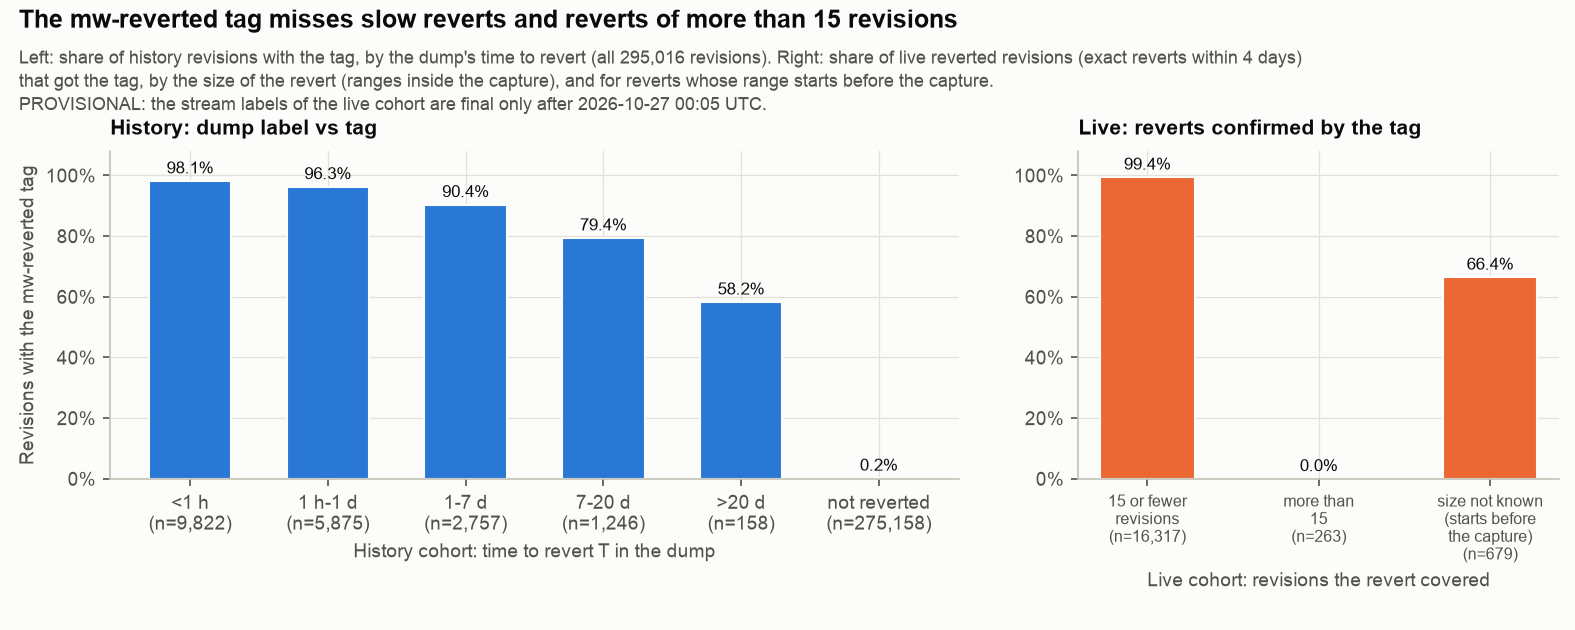

In [7]:
ta = hs["tag_agreement"]
tab = pd.DataFrame([{"time to revert T (dump)": b, "revisions": v["n"], "with mw-reverted tag": v["tag_yes"],
                     "tag share %": round(100 * v["tag_share"], 2)} for b, v in ta["by_T_bucket"].items()])
print("History cohort (dump label vs tag):")
show(tab)
agree = (hist_rev["reverted_any"] == hist_rev["mw_reverted_tag"]).mean()
print(f"overall agreement: {100 * agree:.2f}% (recounted from the Parquet table; summary file: {100 * ta['agreement_share']:.2f}%)")
tc = ls["tag_confirmed_share_of_reverted"]
live_tab = pd.DataFrame([
    {"revisions the revert covered": f"{tc['mw_reverted_max_depth']} or fewer (complete range)", "reverted (n)": tc["range_size_le_max"]["n"],
     "confirmed by the tag": tc["range_size_le_max"]["confirmed"], "share %": round(100 * tc["range_size_le_max"]["share"], 2)},
    {"revisions the revert covered": f"more than {tc['mw_reverted_max_depth']} (complete range)", "reverted (n)": tc["range_size_gt_max"]["n"],
     "confirmed by the tag": tc["range_size_gt_max"]["confirmed"], "share %": round(100 * tc["range_size_gt_max"]["share"], 2)},
    {"revisions the revert covered": "not known: the range starts before the capture", "reverted (n)": tc["range_incomplete"]["n"],
     "confirmed by the tag": tc["range_incomplete"]["confirmed"], "share %": round(100 * tc["range_incomplete"]["share"], 2)}])
print("\nLive cohort (stream label confirmed by the tag; PROVISIONAL):")
show(live_tab)
display(Image(filename=str(figs.tag_agreement_figure(hs, ls))))

## 6. One real revisions document

**What:** Reads one real document of each cohort from the local MongoDB (the same `_id` as `results/sample_documents.json`) and replaces the human editor with a pseudonym (`ingest/build_documents.py`, `pseudonymize_revision`). If MongoDB is not running, it shows the saved sample file instead.

**Why:** The report shows one real `revisions` document (DATA_MODEL.md, section 4). Human names never appear.

**You should see:** Two JSON documents. The history one has a `history` part (reverted after 125 s by the bot ClueBot NG); the live one has a `live` part (seen_ts, revert_risk). `user.name` is `editor_...`.

In [8]:
from bson import json_util
from ingest import build_documents as bd
sample = json.loads((config.RESULTS_DIR / "sample_documents.json").read_text())
n_hex = facts.alias_hex()
try:
    from load_mongo import connect
    db = connect(config.MONGO_URI, 3000)[config.MONGO_DB]
    docs = {c: db[config.COL_REVISIONS].find_one({"_id": sample[c]["_id"]}) for c in ("history", "live")}
    docs = {c: bd.pseudonymize_revision(d, n_hex) for c, d in docs.items()}
    print("read from the local MongoDB (pseudonyms applied here)")
except Exception as exc:
    docs = {c: sample[c] for c in ("history", "live")}
    print(f"MongoDB not reachable ({type(exc).__name__}); showing results/sample_documents.json")
for c, d in docs.items():
    print(f"\n=== {c} cohort")
    print(json_util.dumps(d, indent=2, json_options=json_util.RELAXED_JSON_OPTIONS))

read from the local MongoDB (pseudonyms applied here)

=== history cohort
{
  "_id": "enwiki:1373795093",
  "wiki_db": "enwiki",
  "rev_id": 1373795093,
  "parent_id": 1373794884,
  "cohort": "history",
  "page": {
    "id": 28116865,
    "title": "Adam_Liaw",
    "ns": 0
  },
  "user": {
    "id": null,
    "name": "editor_ec984595df",
    "kind": "registered",
    "key": "editor_ec984595df",
    "is_bot": false,
    "is_anon": false,
    "is_temp": false,
    "edit_count": 2
  },
  "ts": {
    "$date": "2026-09-08T00:12:14Z"
  },
  "hour_utc": 0,
  "size": 20863,
  "size_delta": 29,
  "comment": "added extra information on how he changed throughout his journey",
  "tags": [
    "visualeditor"
  ],
  "mw_reverted_tag": true,
  "is_revert": false,
  "revert_method": null,
  "history": {
    "snapshot": "2026-09",
    "reverted": true,
    "reverted_any": true,
    "secs_to_revert": 125,
    "reverting_rev_id": 1373795417,
    "reverter": {
      "key": "u:13286072",
      "name": "Clue

## 7. Example pages for the Motivation

**What:** Shows the revert timeline of the two example pages for the Motivation (`report/build_facts.py`, `page_timeline`).

**Why:** The Motivation starts from one real page of our data (proposal feedback: Motivation 6/10).

**You should see:** <!--fact:example_slow_page_title-->`World_Figure_Skating_Championships`<!--/fact-->: <!--fact:example_slow_edits-->12<!--/fact--> edits, <!--fact:example_slow_reverted-->9<!--/fact--> reverted, a slow back-and-forth over <!--fact:example_slow_span_h-->39.3<!--/fact--> h. <!--fact:example_fast_page_title-->`Pendulum`<!--/fact-->: vandalism by temporary accounts, reverted after a median of <!--fact:example_fast_T_median_s-->27<!--/fact--> s.

In [9]:
cols = ["time_utc", "editor", "editor_kind", "size_delta", "is_revert", "reverted_20d", "time_to_revert", "reverted_by"]
tl_slow = facts.page_timeline(facts.EXAMPLE_SLOW_PAGE_ID, n_hex)
tl_fast = facts.page_timeline(facts.EXAMPLE_FAST_PAGE_ID, n_hex)
for tl in (tl_slow, tl_fast):
    print(f"=== {tl['page_title'].iloc[0]}")
    show(tl[cols])
    print()
s_slow, s_fast = facts.timeline_summary(tl_slow), facts.timeline_summary(tl_fast)
print(f"{s_slow['title']}: {s_slow['edits']} edits, {s_slow['reverted']} reverted, time to revert from "
      f"{s_slow['T_min_s']:,.0f} s to {s_slow['T_max_s']:,.0f} s (median {s_slow['T_median_s']:,.0f} s), "
      f"{s_slow['first_utc']} to {s_slow['last_revert_utc']}.")

=== World_Figure_Skating_Championships
| time_utc            | editor            | editor_kind   |   size_delta | is_revert   | reverted_20d   | time_to_revert   | reverted_by       |
|---------------------|-------------------|---------------|--------------|-------------|----------------|------------------|-------------------|
| 2026-09-08 04:36:46 | editor_bdbff746bb | registered    |          -17 | False       | True           | 4.0 h            | editor_4e584fa272 |
| 2026-09-08 08:37:38 | editor_4e584fa272 | registered    |           17 | True        | True           | 13.4 h           | editor_bdbff746bb |
| 2026-09-08 22:04:15 | editor_bdbff746bb | registered    |          -17 | True        | True           | 2.9 h            | editor_4e584fa272 |
| 2026-09-09 00:55:23 | editor_4e584fa272 | registered    |           17 | True        | True           | 1.7 h            | editor_bdbff746bb |
| 2026-09-09 02:38:26 | editor_bdbff746bb | registered    |          -17 | True        | Tr

## Check against FACTS.md

**What:** Compares the key numbers of this notebook with `report/FACTS.md`. Then it checks every number in the text of this notebook (the fact markers) against FACTS.md.

**Why:** The report uses FACTS.md. If a number here is different, the data or the code changed: tell the Report+GenAI owner before you copy any number.

**You should see:** Two tables with one row per number, and the lines `OK: all ... numbers match FACTS.md` and `OK: all ... numbers in the text match FACTS.md`. `DIFFERENT` means a number changed (normal for PROVISIONAL numbers after the live refresh). Then run `report/build_facts.py` and `report/sync_notebook_text.py` again.

In [10]:
facts.check({
    "history_file_rows": file_rows,
    "history_revisions": len(hist_rev),
    "live_revisions": len(live_rev),
    "history_edits_temporary": int((hist_rev["user_kind"] == "temporary").sum()),
    "history_revert_rate_non_bot_pct": 100 * rate_nb,
    "history_median_T_s": t_all.median(),
    "history_median_T_non_bot_h": t_nb.median() / 3600,
    "history_median_T_4d_s": t_4d.median(),
    "live_median_T_s": t_live.median(),
    "history_T_within_1h_pct": 100 * (t_all < 3600).mean(),
    "history_T_within_1d_pct": 100 * (t_all < 86400).mean(),
    "history_file_vs_wikistats_pct": a_file,
    "history_tag_agreement_pct": 100 * agree,
    "live_tag_confirmed_range_le_15_pct": 100 * tc["range_size_le_max"]["share"],
    "live_tag_confirmed_range_gt_15_pct": 100 * tc["range_size_gt_max"]["share"],
    "live_tag_confirmed_range_incomplete_pct": 100 * tc["range_incomplete"]["share"],
    "capture_page_change_gaps": sp["streams"][config.STREAM_PAGE_CHANGE]["gaps"],
    "capture_revert_risk_gaps": len(gaps[gaps["stream"] == config.STREAM_REVERT_RISK]),
    "live_followup_max_d": live_rev["followup_s"].max() / 86400,
    "example_slow_page_title": s_slow["title"],
    "example_slow_reverted": s_slow["reverted"],
    "example_fast_T_median_s": s_fast["T_median_s"],
})
print()
from report import sync_notebook_text
sync_notebook_text.check_markers(HW2 / "notebooks" / "01_data.ipynb")
print(f"\nnotebook time: {time.time() - T0:.0f} s")

| key                                     | FACTS.md                           | notebook                           | status      | result   |
|-----------------------------------------|------------------------------------|------------------------------------|-------------|----------|
| history_file_rows                       | 300,564                            | 300,564                            | FINAL       | OK       |
| history_revisions                       | 295,016                            | 295,016                            | FINAL       | OK       |
| live_revisions                          | 279,466                            | 279,466                            | PROVISIONAL | OK       |
| history_edits_temporary                 | 38,164                             | 38,164                             | FINAL       | OK       |
| history_revert_rate_non_bot_pct         | 7.43                               | 7.43                               | FINAL       | OK       |

Numbers in the text of 01_data.ipynb (fact markers):
| cell   | key                                     | text                               | FACTS.md                           | result   |
|--------|-----------------------------------------|------------------------------------|------------------------------------|----------|
| 0      | history_revisions                       | 295,016                            | 295,016                            | OK       |
| 0      | live_revisions                          | 279,466                            | 279,466                            | OK       |
| 0      | history_revert_rate_non_bot_pct         | 7.43                               | 7.43                               | OK       |
| 0      | history_median_T_h                      | 1.02                               | 1.02                               | OK       |
| 6      | history_file_rows                       | 300,564                            | 300,564                      